## Part C — Hinglish failure analysis and remedy (Reviewer 1 comment 3, Reviewer 2 comment 1)

Language-view Macro-F1 of the reference model (mean of 3 tasks / primary):
{'concat': (0.8584, 0.9196), 'english': (0.8205, 0.8944), 'hindi': (0.6793, 0.7842), 'hinglish': (0.4376, 0.5605)}
  Spearman(subword fragmentation, Hinglish error) = +0.201
  Spearman(English-lexical share, Hinglish error) = -0.320
  Spearman(length (words), Hinglish error) = +0.088
               factor  bin    n  hinglish_error  english_error
subword fragmentation  low 1018           0.310          0.083
subword fragmentation  mid 1012           0.508          0.114
subword fragmentation high 1006           0.541          0.120
English-lexical share  low 1015           0.604          0.117
English-lexical share  mid 1012           0.500          0.103
English-lexical share high 1009           0.253          0.097
       length (words)  low 1094           0.386          0.112
       length (words)  mid  967           0.468          0.085
       length (words) high  975           0.512          0.120

Top Hingl

  viewdrop_p0.5 s11 ep1: dev mt_f1=0.7469 P=0.8837 S=0.6206 V=0.7365


  viewdrop_p0.5 s11 ep2: dev mt_f1=0.8418 P=0.9173 S=0.7872 V=0.8208


  viewdrop_p0.5 s11 ep3: dev mt_f1=0.8515 P=0.9177 S=0.8043 V=0.8325

 view                         concat  english   hindi  hinglish
model                                                         
reference (concat training)  0.9196   0.8944  0.7842    0.5605
view-dropout p=0.5           0.9170   0.9008  0.8700    0.7982


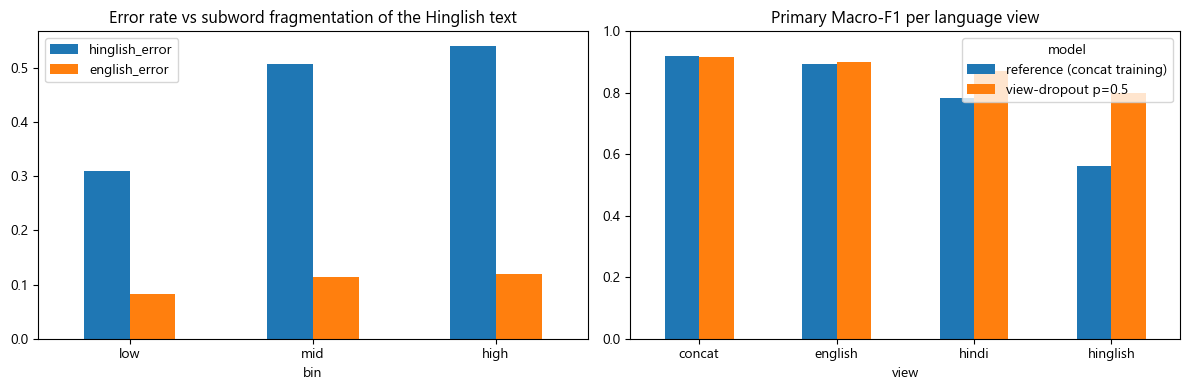

In [11]:
# ============================================================================
# HINGLISH FAILURE ANALYSIS + REMEDY  (Reviewer 1 comment 3, Reviewer 2 comment 1)
# ============================================================================
# KEY FACT about the original pipeline: training text = title + English + Hindi + Hinglish CONCATENATED, but language-wise
# evaluation feeds ONE column at a time -> an input-distribution shift the model never saw. The `viewdrop` arm tests the fix.
print('Language-view Macro-F1 of the reference model (mean of 3 tasks / primary):')
V = REF_RES['views']; print({k: (round(v['mt_f1'], 4), round(v['primary']['f1_macro'], 4)) for k, v in V.items()})

hl = test_df.copy(); en_txt, hg_txt = hl['text_en'].astype(str), hl['Hinglish'].astype(str)
P_h = make_predictor(ref_model, 'primary')
ph = P_h(hg_txt.tolist()).argmax(1); pe = P_h(en_txt.tolist()).argmax(1); y = hl['primary_label'].values
hl['err_hinglish'] = (ph != y).astype(int); hl['err_english'] = (pe != y).astype(int)
hl['frag'] = [len(tok.tokenize(t)) / max(1, len(t.split())) for t in hg_txt]                       # subword fragmentation ratio
hl['eng_overlap'] = [len({norm_word(w) for w in h.split()} & {norm_word(w) for w in e.split()}) / max(1, len(h.split())) for h, e in zip(hg_txt, en_txt)]  # lexical share shared with English (code-mix proxy)
hl['n_words'] = [len(t.split()) for t in hg_txt]
rows = []
for col, nm in [('frag', 'subword fragmentation'), ('eng_overlap', 'English-lexical share'), ('n_words', 'length (words)')]:
    try: hl['bin'] = pd.qcut(hl[col], 3, labels=['low', 'mid', 'high'], duplicates='drop')
    except ValueError: continue
    for b, d in hl.groupby('bin'): rows.append(dict(factor=nm, bin=b, n=len(d), hinglish_error=d.err_hinglish.mean(), english_error=d.err_english.mean()))
    rho = stats.spearmanr(hl[col], hl.err_hinglish)[0]; print(f'  Spearman({nm}, Hinglish error) = {rho:+.3f}')
fail = pd.DataFrame(rows); fail.to_csv(OUT('tables', 'hinglish_failure_factors.csv'), index=False); print(fail.round(3).to_string(index=False))

def top_confusions(y, p, k=5):
    cm = confusion_matrix(y, p, labels=range(N_CLS['primary'])); np.fill_diagonal(cm, 0)
    return [(CLASS_NAMES['primary'][i][:26], CLASS_NAMES['primary'][j][:26], int(cm[i, j])) for i, j in zip(*np.unravel_index(np.argsort(-cm, axis=None)[:k], cm.shape))]
print('\nTop Hinglish confusions:', top_confusions(y, ph)); print('Top English confusions :', top_confusions(y, pe))

# which words mislead the model on Hinglish errors? (attribution-based error analysis)
err_ix = np.where(ph != y)[0][:600]
if len(err_ix):
    att_h = occlusion_attributions(P_h, [hg_txt.iloc[i] for i in err_ix], None, mask_token=MASK)
    mis_h, _ = mine_misleading(att_h, y[err_ix].tolist(), min_count=2)
    json.dump({w: list(v) for w, v in mis_h.items()}, open(OUT('xai', 'hinglish_misleading_tokens.json'), 'w'), ensure_ascii=False, indent=1)
    print('Words that mislead on Hinglish errors:', list(mis_h)[:20])

# remedy: language-view dropout during training (p=0.5 of rows replaced by a single language view)
vd = train_run('viewdrop_p0.5', REF_SEED, (1, 1, REF_ALPHA), train_df, dev_sel, test_df, epochs=CFG.EPOCHS, view_dropout_p=0.5)
cmp_rows = []
for nm, r in [('reference (concat training)', REF_RES), ('view-dropout p=0.5', vd)]:
    for view, m in r['views'].items(): cmp_rows.append(dict(model=nm, view=view, mt_f1=m['mt_f1'], primary_f1=m['primary']['f1_macro']))
cmp_df = pd.DataFrame(cmp_rows); cmp_df.to_csv(OUT('tables', 'viewdrop_comparison.csv'), index=False)
print('\n', cmp_df.pivot(index='model', columns='view', values='primary_f1').round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fail[fail.factor == 'subword fragmentation'].set_index('bin')[['hinglish_error', 'english_error']].plot.bar(ax=ax[0], rot=0); ax[0].set_title('Error rate vs subword fragmentation of the Hinglish text')
cmp_df.pivot(index='view', columns='model', values='primary_f1').plot.bar(ax=ax[1], rot=0); ax[1].set_title('Primary Macro-F1 per language view'); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(OUT('figs', 'hinglish_analysis.png'), dpi=300, bbox_inches='tight'); plt.show()


In [12]:
# ============================================================================
# AUTO-GENERATED DRAFT OF THE "RESPONSE TO REVIEWERS" ENTRIES THIS NOTEBOOK SUPPORTS
# Numbers are pulled from your own results; read it, edit it, and do NOT submit claims your numbers don't support.
# ============================================================================
def pct(x): return f'{100 * x:.2f}%'
best = agg.loc[agg.alpha3 == a_star].iloc[0]; half = agg.loc[np.isclose(agg.alpha3, 0.5)].iloc[0]
sh_f = final_df[final_df.arm == 'shap'].iloc[0]; rd_f = final_df[final_df.arm == 'random'].iloc[0]; pl_f = final_df[final_df.arm == 'plain'].iloc[0]; rf_f = final_df[final_df.arm.str.startswith('reference')].iloc[0]
md = f"""# Response to Reviewers — draft entries generated {time.strftime('%Y-%m-%d')}  (profile: {CFG.PROFILE}, seeds: {CFG.SEEDS})

## Reviewer 1, comment 4 — α3 = 0.5 lacks justification / sensitivity analysis
**Concern.** α3 was tuned empirically with no theoretical justification and no in-depth sensitivity analysis.
**Response.** We replaced the single-model accuracy table by a retrained sweep over α3 ∈ {CFG.ALPHAS} ({len(CFG.SEEDS)} seeds each), reporting Macro-F1 for all three tasks, with α3 selected on a held-out development split only. Dev-selected α3* = {a_star}; the dev plateau (within one SE of the best) is {plateau}. Mean-of-tasks test Macro-F1: α3* = {best['test_mt_f1_mean']:.4f}, α3 = 0.5 → {half['test_mt_f1_mean']:.4f}. We additionally justify the weight via (i) gradient-balance analysis at the shared layer, (ii) learned homoscedastic-uncertainty weights, and (iii) paired bootstrap tests against α3 = 0.5 (Table X, Fig. X).
**Action.** New Section VIII-B, Table 19 (replaced), Fig. X (sensitivity/Pareto), Fig. Y (gradient diagnostics).

## Reviewer 1 comment 5 / Reviewer 2 comment 5 — SHAP is only post-hoc
**Concern.** Explanations are never used to improve the model.
**Response.** We close the loop: word-level attributions (leave-one-out, validated against permutation-sampling Shapley values: Spearman = {AGREE['spearman']:.2f}, top-3 overlap = {AGREE['topk_overlap']:.2f}) are used to (a) mask each training example's top-attributed word and (b) build counterfactuals for words mined from validation errors that push predictions to the wrong class; the model is fine-tuned and each round is accepted only if development Macro-F1 improves. Against matched controls, the mean-of-tasks test Macro-F1 is: reference {rf_f.test_mt_f1:.4f} → SHAP-guided {sh_f.test_mt_f1:.4f} (random-masking control {rd_f.test_mt_f1:.4f}; plain continued training {pl_f.test_mt_f1:.4f}). Hinglish-view primary F1 changes by {sh_f.d_hinglish:+.4f} (SHAP-guided). Single-token flip rate: {rf_f.flip_rate:.3f} → {sh_f.flip_rate:.3f}; comprehensiveness AOPC: {rf_f.comp_aopc:.3f} → {sh_f.comp_aopc:.3f}.
**Action.** New Section VII-E (feedback loop), Table X, Fig. Z. [Edit this paragraph honestly if shap − random is not significant — see the bootstrap printed in cell 9.]

## Reviewer 1, comment 7 — ontology / keyword constraints for Waste vs Health & Sanitation
**Response.** We add an attribution-mined lexicon (plus optional hand-written ontology) as a post-hoc constraint, β tuned on dev. Test primary Macro-F1 {LEX_RES['f1_before']:.4f} → {LEX_RES['f1_after']:.4f}; errors on the dominant pair ({LEX_RES['pair'][0]} ↔ {LEX_RES['pair'][1]}) {LEX_RES['pair_errors_before']} → {LEX_RES['pair_errors_after']}.

## Reviewer 1 comment 3 / Reviewer 2 comment 1 — Hinglish
**Response.** Error analysis by subword fragmentation, English-lexical share and length (hinglish_failure_factors.csv); the training/evaluation view mismatch (trilingual concatenation at training, single-language columns at evaluation) is identified and addressed with language-view dropout. Primary Macro-F1 on the Hinglish view: reference {REF_RES['views']['hinglish']['primary']['f1_macro']:.4f} → view-dropout {vd['views']['hinglish']['primary']['f1_macro']:.4f}.

## NOT covered by this notebook (still to do for the resubmission)
R1-2 / R2-3 quality metrics for the synthetic data and per-LLM ablation; R2-4 SOTA Indic baselines; R1-6 (remote-sensing suggestion, optional: you may politely decline — see editor's note about reviewer-suggested references); R1-8 future-work feasibility paragraph. R1-1 asks for CNN/BiLSTM baselines which already appear in Tables 11–15 of the submitted PDF — point the reviewer there.
"""
open(OUT('tables', 'response_to_reviewers_draft.md'), 'w', encoding='utf-8').write(md); print(md)
print('\nAll outputs under:', CFG.OUT_DIR)


# Response to Reviewers — draft entries generated 2026-11-02  (profile: quick, seeds: [11])

## Reviewer 1, comment 4 — α3 = 0.5 lacks justification / sensitivity analysis
**Concern.** α3 was tuned empirically with no theoretical justification and no in-depth sensitivity analysis.
**Response.** We replaced the single-model accuracy table by a retrained sweep over α3 ∈ [0.25, 0.5, 1.0] (1 seeds each), reporting Macro-F1 for all three tasks, with α3 selected on a held-out development split only. Dev-selected α3* = 0.5; the dev plateau (within one SE of the best) is [0.5]. Mean-of-tasks test Macro-F1: α3* = 0.8584, α3 = 0.5 → 0.8584. We additionally justify the weight via (i) gradient-balance analysis at the shared layer, (ii) learned homoscedastic-uncertainty weights, and (iii) paired bootstrap tests against α3 = 0.5 (Table X, Fig. X).
**Action.** New Section VIII-B, Table 19 (replaced), Fig. X (sensitivity/Pareto), Fig. Y (gradient diagnostics).

## Reviewer 1 comment 5 / Reviewer 2 com